<a href="https://colab.research.google.com/github/seonilj/data-science-python-neuroscience/blob/main/assignments/task2_spike_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How to define and detect spikes in noisy neural signals

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Data Audit
(Part 1)

In [4]:
# 1. Load the data
data = np.load("/content/sample_data/spike_data.npz")

In [6]:
# 2. Check available arrays
print("Arrays:", data.files)

Arrays: ['t', 'raw_data']


In [7]:
# Bring data through array names
t = data["t"]
raw_data = data["raw_data"]

In [9]:
# 3. Check basic properties

print(f"t shape: {t.shape}") # array's size & dimension
print(f"raw_data shape: {raw_data.shape}")

print(f"t data type: {t.dtype}")
print(f"raw_data type: {raw_data.dtype}")

print(f"Number of samples: {len(t)}")
print(f"First time point: {t[0]}")
print(f"Last time point: {t[-1]}")

t shape: (10000,)
raw_data shape: (10000,)
t data type: float64
raw_data type: float64
Number of samples: 10000
First time point: 0.0
Last time point: 9.999


In [14]:
# 4. Sampling interval & frequency

dt = np.diff(t) # sampling interval: difference between continuous values (substract) -> sampling frequency 계산
fs = 1 / np.median(dt) # 공식: elapsed time (s) = sampling frequency (Hz) * interval(t)

print(f"Mean sampling interval (s): {np.mean(dt)}")
print(f"Median sampling interval (s): {np.median(dt)}") # less effect by extreme values (better to exclude outlier)
print(f"Sampling frequency (Hz): {fs}") # 1초간 측정한 샘플개수 (samples/second) = fs


Mean sampling interval (s): 0.001
Median sampling interval (s): 0.0010000000000000009
Sampling frequency (Hz): 999.9999999999991


In [18]:
# 5. Recording duration
print(f"Time span (s): {t[-1] - t[0]}") # elapsed time of 1st-last samples
print(f"Duration based on sample count (s): {len(t) / fs}") # N samples per sec: 전체샘플/초당n개(속도)

Time span (s): 9.999
Duration based on sample count (s): 10.000000000000009


In [19]:
# 6. Voltage summary
print(f"Min voltage: {np.min(raw_data)}")
print(f"Max voltage: {np.max(raw_data)}")
print(f"Mean voltage: {np.mean(raw_data)}")
print(f"Median voltage: {np.median(raw_data)}")
print(f"Standard deviation: {np.std(raw_data)}")

Min voltage: -1.69098912315189
Max voltage: 6.201962575902169
Mean voltage: 0.07688186859453112
Median voltage: 0.03541220827672234
Standard deviation: 0.7344060361724829


# 2. Signal Exploration
(Part 2)

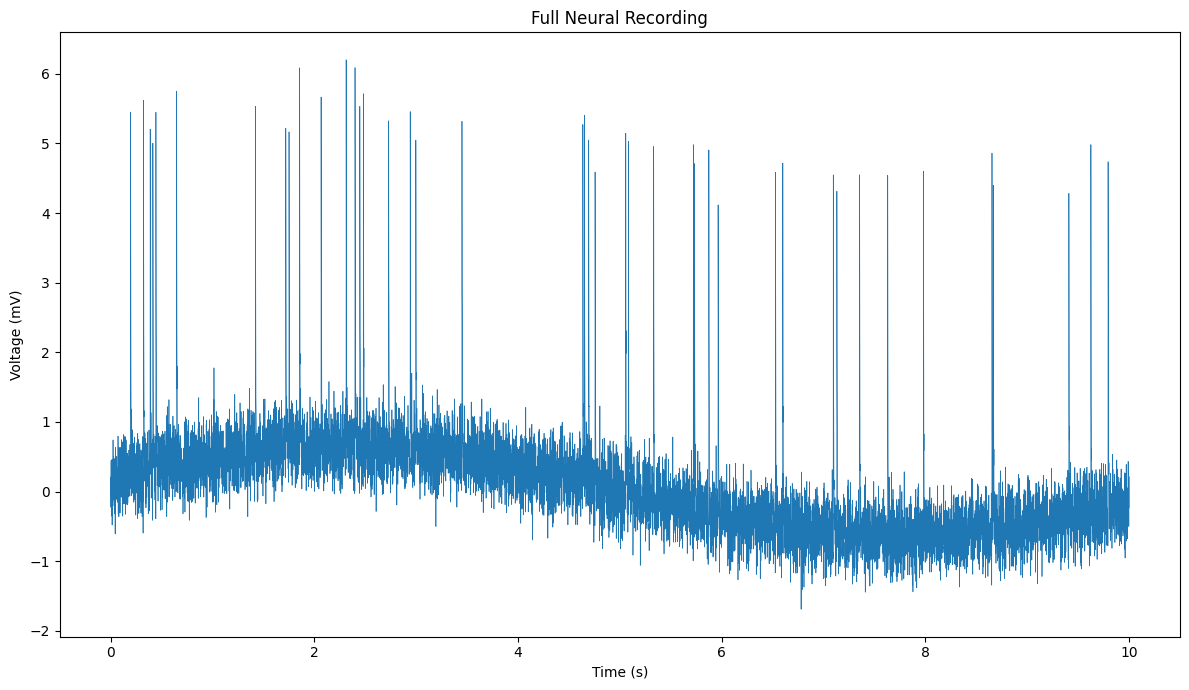

In [23]:
# Full recording (10초간의 큰 흐름 확인)

plt.figure(figsize=(12, 7))
plt.plot(t, raw_data, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Voltage (mV)")
plt.title("Full Neural Recording")

plt.tight_layout() # Adjust spacing so labels don't get cut off
plt.show()

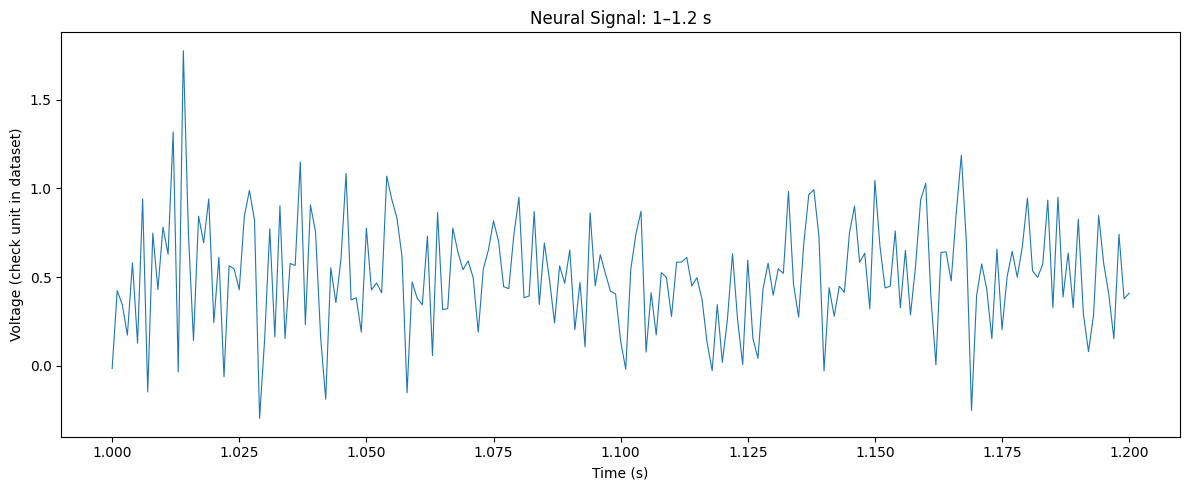

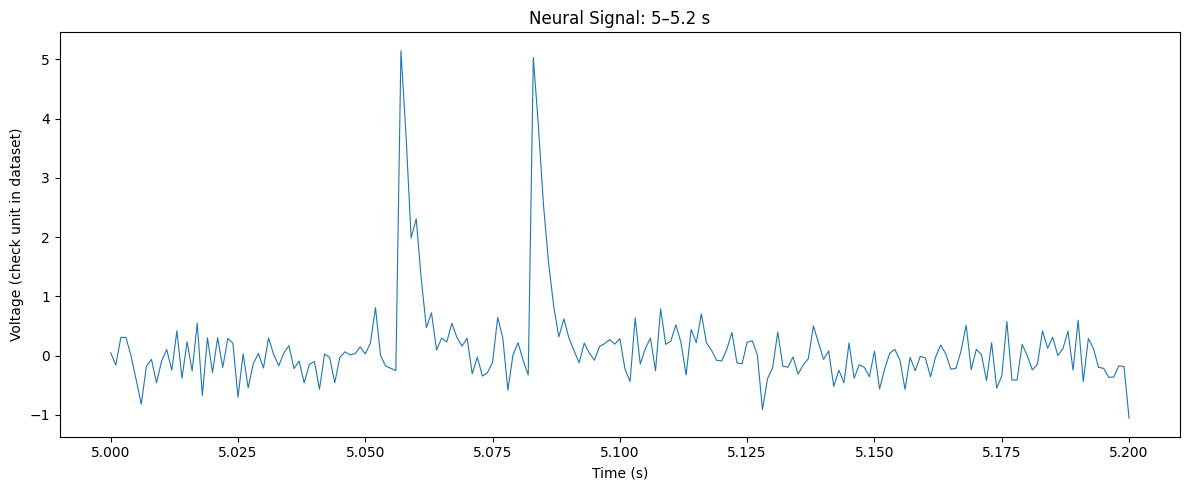

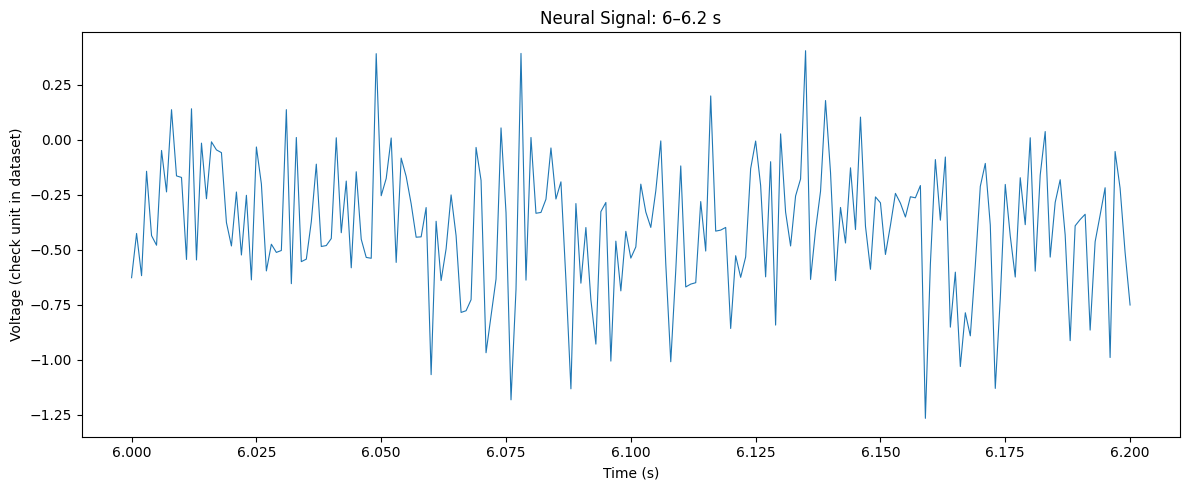

In [28]:
# Inspect two short intervals (s)
intervals = [(1, 1.2), (5, 5.2), (6, 6.2)]

# Repeat the same steps for each interval
for start, end in intervals:
    # Select samples (timestamps fall within this interval)
    mask = (t >= start) & (t <= end)
    # Create a separate figure for this interval
    plt.figure(figsize=(12, 5))
    # Plot only the selected time and voltage values
    plt.plot(t[mask], raw_data[mask], linewidth=0.8)

    plt.xlabel("Time (s)")
    plt.ylabel("Voltage (check unit in dataset)")
    plt.title(f"Neural Signal: {start}–{end} s")

    plt.tight_layout()
    plt.show()

In [34]:
# Compare the three intervals

print("---Comparison of selected intervals---\n")

for start, end in intervals:
  mask = (t >= start) & (t <= end) # bool (어떤 시간 데이터 선택할지 여부)
  segment = raw_data[mask] # voltage values from 'mask'

  print(f"Interval: {start - end}")
  print(f"Min: {np.min(segment):.3f}")
  print(f"Max: {np.max(segment):.3f}")
  print(f"Mean: {np.mean(segment):.3f}")
  print(f"Median: {np.median(segment):.3f}")
  print(f"Std: {np.std(segment):.3f}")
  print()

---Comparison of selected intervals---

Interval: -0.19999999999999996
Min: -0.297
Max: 1.776
Mean: 0.508
Median: 0.498
Std: 0.310

Interval: -0.20000000000000018
Min: -1.060
Max: 5.146
Mean: 0.126
Median: 0.010
Std: 0.768

Interval: -0.20000000000000018
Min: -1.267
Max: 0.404
Mean: -0.392
Median: -0.392
Std: 0.300



# 3. Define Rules for the Spike
(Part 3)

Threshold: 2.280
Number of candidate events: 43

1. Time: 0.195 sec,  Voltage: 5.451
2. Time: 0.322 sec,  Voltage: 5.621
3. Time: 0.388 sec,  Voltage: 5.206
4. Time: 0.414 sec,  Voltage: 5.005
5. Time: 0.444 sec,  Voltage: 5.448
6. Time: 0.647 sec,  Voltage: 5.750
7. Time: 1.421 sec,  Voltage: 5.534
8. Time: 1.719 sec,  Voltage: 5.217
9. Time: 1.751 sec,  Voltage: 5.167
10. Time: 1.855 sec,  Voltage: 6.086
11. Time: 2.066 sec,  Voltage: 5.667
12. Time: 2.312 sec,  Voltage: 6.202
13. Time: 2.399 sec,  Voltage: 6.089
14. Time: 2.446 sec,  Voltage: 5.533
15. Time: 2.481 sec,  Voltage: 5.714
16. Time: 2.729 sec,  Voltage: 5.325
17. Time: 2.941 sec,  Voltage: 5.457
18. Time: 2.996 sec,  Voltage: 5.048
19. Time: 3.449 sec,  Voltage: 5.318
20. Time: 4.636 sec,  Voltage: 5.273
21. Time: 4.652 sec,  Voltage: 5.406
22. Time: 4.693 sec,  Voltage: 5.050
23. Time: 4.756 sec,  Voltage: 4.590
24. Time: 5.057 sec,  Voltage: 5.146
25. Time: 5.060 sec,  Voltage: 2.308
26. Time: 5.083 sec,  Voltage: 5.03

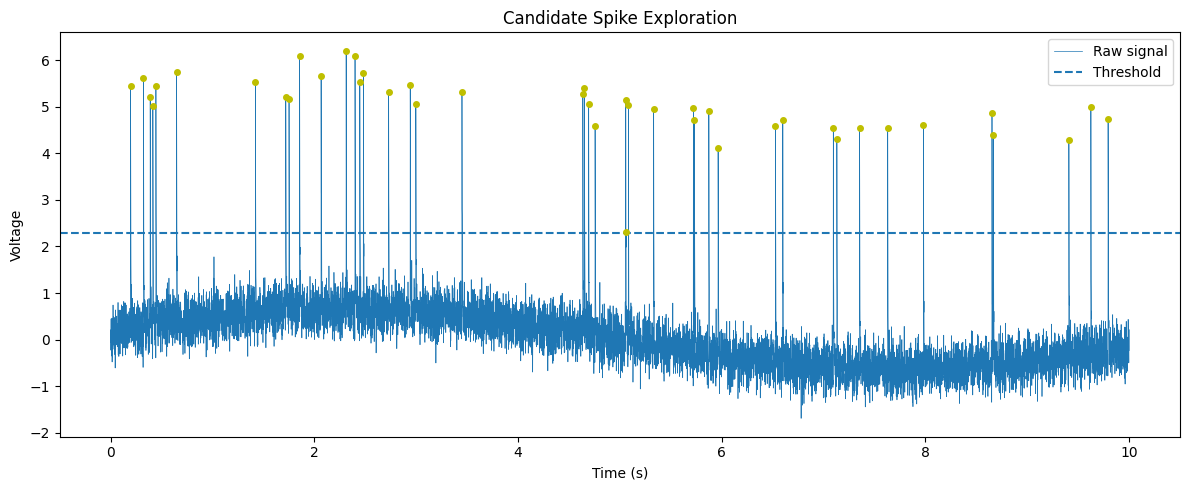

In [50]:
# Find candidate spikes

# 1. Voltage threshold definition
threshold = np.mean(raw_data) + 3 * np.std(raw_data) #mean: 0.077, std: 0.734 -> more than 3 times higher

print(f"Threshold: {threshold:.3f}")

# 2. Find candidate spike events
i = 0 # 1st 샘플부터 확인하는 인덱스
spike_times = []

while i < len(raw_data):
  if raw_data[i] > threshold:
    # Count event start time (넘기 시작한 위치 기록)
    spike_times.append(i)
    # Skip the further samples above threshold (이후의 넘는 나머지샘플 건너뛰어 같은 이벤트 여러번 세지않게 함)
    while i < len(raw_data) and raw_data[i] > threshold:
            i += 1
  else:
    i += 1

print(f"Number of candidate events: {len(spike_times)}\n")

# 3. Show 'time & voltage' set for each candidate event
for number, index in enumerate(spike_times, start=1):
    print(
        f"{number}. Time: {t[index]:.3f} sec, ",
        f"Voltage: {raw_data[index]:.3f}"
    )

# 4. Plot signal & threshold
plt.figure(figsize=(12, 5))
plt.plot(t, raw_data, linewidth=0.5, label="Raw signal")
plt.axhline(threshold, linestyle="--", label="Threshold")

for index in spike_times:
    plt.plot(t[index], raw_data[index], "yo", markersize=4)

plt.xlabel("Time (s)")
plt.ylabel("Voltage")
plt.title("Candidate Spike Exploration")
plt.legend()

plt.tight_layout()
plt.show()


In [52]:
# Test the spike detection rule with simple data

test_data = np.array([1, 7, 5, 2, 2, 9, 5, 4])
test_threshold = 3

test_events = []
i = 0

while i < len(test_data):
    if test_data[i] > test_threshold:
        test_events.append(i)

        while i < len(test_data) and test_data[i] > test_threshold:
            i += 1
    else:
        i += 1

print("Detected event positions:", test_events)
print("Number of events:", len(test_events))

Detected event positions: [1, 5]
Number of events: 2


## Detection Specification
I made and use the voltage threshold to detect candidate spike events. The threshold is set to the mean voltage of the full recording plus three times its standard deviation, giving a threshold of around 2.280.

A candidate event is detected when the voltage increases above the threshold, and its consecutive samples above the threshold within the group are counted as one event.

This method is simple, but it has limitations, and this is why those detected events are better to be treated as candidates than confirmed spikes. Noise may be detected as a candidate event, real spikes below the threshold may be missed, and a small drop below the threshold may cause one peak to become multiple events records.

To test this logic, I made a small example array and a threshold of 3. The code detected two positions as intended. When this ruls was applied, 43 candidates events are counted, and I also plotted the signal, threshold, and those detected event positions.